In [1]:

# ==========================================
# CELL 1: SETUP AND DATASET DOWNLOAD
# ==========================================

import torch
import os
import subprocess
from pathlib import Path

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not available. Enable T4 GPU.")

# Download tree segmentation dataset
dataset_path = "/content/tree-segmentation-dataset"

if not os.path.exists(dataset_path):
    subprocess.run([
        "git", "clone",
        "https://github.com/gabrieldgf4/tree-segmentation-dataset.git",
        dataset_path
    ], check=True)

print("\nDataset downloaded successfully!")

# Display folder structure
print("\nDATASET FOLDER STRUCTURE")
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) +
              f" ({len(files)} files)")


PyTorch version: 2.14.1+cpu
GPU available: False

Dataset downloaded successfully!

DATASET FOLDER STRUCTURE
tree-segmentation-dataset (2 files)
  .git (5 files)
    objects (0 files)
      pack (3 files)
      info (0 files)
    branches (0 files)
    logs (1 files)
      refs (0 files)
    info (1 files)
    refs (0 files)
      remotes (0 files)
      heads (1 files)
      tags (0 files)
    hooks (14 files)
  g2 (0 files)
    tree-mask (11 files)
    tree (11 files)
    tree-seg (11 files)
    ground-mask (11 files)
  g3 (0 files)
    tree-mask (11 files)
    tree (11 files)
    tree-seg (11 files)
    ground-mask (11 files)
  g4 (0 files)
    tree-mask (10 files)
    tree (10 files)
    tree-seg (10 files)
    ground-mask (10 files)
  g1 (0 files)
    tree-mask (11 files)
    tree (11 files)
    tree-seg (11 files)
    ground-mask (11 files)
  g5 (0 files)
    tree-mask (11 files)
    tree (11 files)
    tree-seg (11 files)
    ground-mask (11 files)


In [3]:


# CELL 2: INSPECT DATASET AND MASKS

import os
from pathlib import Path
from PIL import Image
import numpy as np
import torch

dataset_path = "/content/tree-segmentation-dataset"

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

print("\nFILE DETAILS")

for group in ["g1", "g2", "g3", "g4", "g5"]:
    print(f"\n--- {group} ---")

    for folder in ["tree", "tree-mask", "tree-seg", "ground-mask"]:
        folder_path = Path(dataset_path) / group / folder

        files = sorted([
            f for f in folder_path.iterdir()
            if f.is_file() and f.suffix.lower() in valid_extensions
        ])

        print(f"\n{folder}: {len(files)} image files")

        if files:
            print("Sample filenames:", [f.name for f in files[:3]])

            sample = Image.open(files[0])
            print("Sample size:", sample.size)
            print("Image mode:", sample.mode)

            if "mask" in folder:
                arr = np.array(sample)
                print("Unique pixel values:", np.unique(arr)[:20])



GPU available: False

FILE DETAILS

--- g1 ---

tree: 10 image files
Sample filenames: ['i1.png', 'i10.png', 'i2.png']
Sample size: (364, 600)
Image mode: RGB

tree-mask: 10 image files
Sample filenames: ['i10b.png', 'i1b.png', 'i2b.png']
Sample size: (364, 600)
Image mode: 1
Unique pixel values: [False  True]

tree-seg: 10 image files
Sample filenames: ['i10r.png', 'i1r.png', 'i2r.png']
Sample size: (364, 600)
Image mode: RGB

ground-mask: 10 image files
Sample filenames: ['i10c.png', 'i1c.png', 'i2c.png']
Sample size: (364, 600)
Image mode: 1
Unique pixel values: [False  True]

--- g2 ---

tree: 10 image files
Sample filenames: ['i1.png', 'i10.png', 'i2.png']
Sample size: (1000, 745)
Image mode: RGBA

tree-mask: 10 image files
Sample filenames: ['i10b.png', 'i1b.png', 'i2b.png']
Sample size: (1000, 745)
Image mode: 1
Unique pixel values: [False  True]

tree-seg: 10 image files
Sample filenames: ['i10r.png', 'i1r.png', 'i2r.png']
Sample size: (1000, 745)
Image mode: RGBA

ground-mask:

In [5]:

# CELL 3: VERIFY IMAGE AND MASK PAIRS

from pathlib import Path
from PIL import Image

dataset_path = Path("/content/tree-segmentation-dataset")

total_pairs = 0
mismatches = []

for group in ["g1", "g2", "g3", "g4", "g5"]:
    image_folder = dataset_path / group / "tree"
    mask_folder = dataset_path / group / "tree-mask"

    for image_path in image_folder.glob("*.png"):
        mask_path = mask_folder / (image_path.stem + "b.png")

        if not mask_path.exists():
            print("Missing mask:", image_path.name, "in", group)
            continue

        image_size = Image.open(image_path).size
        mask_size = Image.open(mask_path).size

        total_pairs += 1

        if image_size != mask_size:
            mismatches.append(
                (group, image_path.name, image_size, mask_size)
            )

print("Total matched image-mask pairs:", total_pairs)
print("Dimension mismatches:", len(mismatches))

for item in mismatches:
    print(item)

print("\nPAIR VERIFICATION COMPLETED")


Total matched image-mask pairs: 49
Dimension mismatches: 0

PAIR VERIFICATION COMPLETED


Total image-mask pairs: 49

DATASET SPLIT
Training images: 34
Validation images: 7
Testing images: 8

BATCH VERIFICATION
Image batch shape: torch.Size([2, 3, 128, 128])
Mask batch shape: torch.Size([2, 1, 128, 128])
Mask unique values: tensor([0., 1.])


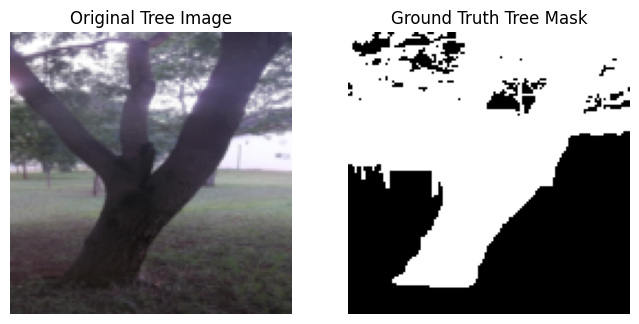


DATASET PREPARATION COMPLETED!


In [7]:

# ==========================================
# CELL 4: DATASET LOADING AND PREPROCESSING
# ==========================================

import torch
from torch.utils.data import Dataset, DataLoader, random_split
from PIL import Image
from pathlib import Path
import numpy as np
import random
import matplotlib.pyplot as plt

# Settings
IMAGE_SIZE = 128
BATCH_SIZE = 2
SEED = 42

torch.manual_seed(SEED)
random.seed(SEED)

dataset_path = Path("/content/tree-segmentation-dataset")

# Collect image-mask pairs
image_mask_pairs = []

for group in ["g1", "g2", "g3", "g4", "g5"]:

    image_folder = dataset_path / group / "tree"
    mask_folder = dataset_path / group / "tree-mask"

    for image_path in sorted(image_folder.glob("*.png")):

        mask_path = mask_folder / (image_path.stem + "b.png")

        if mask_path.exists():
            image_mask_pairs.append((image_path, mask_path))

print("Total image-mask pairs:", len(image_mask_pairs))


# Custom Dataset Class
class TreeDataset(Dataset):

    def __init__(self, pairs, augment=False):
        self.pairs = pairs
        self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):

        image_path, mask_path = self.pairs[index]

        image = Image.open(image_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        # Resize image and mask
        image = image.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.BILINEAR
        )

        mask = mask.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.NEAREST
        )

        # Convert to arrays
        image = np.array(image, dtype=np.float32) / 255.0
        mask = np.array(mask, dtype=np.float32)

        # Convert mask to binary values: 0 or 1
        mask = (mask > 0).astype(np.float32)

        # Horizontal flip augmentation
        if self.augment and random.random() < 0.5:
            image = np.fliplr(image).copy()
            mask = np.fliplr(mask).copy()

        # Convert to PyTorch tensors
        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


# Split dataset: 70% train, 15% validation, 15% test
total = len(image_mask_pairs)
train_size = int(0.70 * total)
val_size = int(0.15 * total)
test_size = total - train_size - val_size

generator = torch.Generator().manual_seed(SEED)

train_pairs, val_pairs, test_pairs = random_split(
    image_mask_pairs,
    [train_size, val_size, test_size],
    generator=generator
)

# Create datasets
train_dataset = TreeDataset(train_pairs, augment=True)
val_dataset = TreeDataset(val_pairs, augment=False)
test_dataset = TreeDataset(test_pairs, augment=False)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("\nDATASET SPLIT")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

# Check one batch
images, masks = next(iter(train_loader))

print("\nBATCH VERIFICATION")
print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Mask unique values:", torch.unique(masks))

# Display one sample
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(images[0].permute(1, 2, 0))
plt.title("Original Tree Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(masks[0, 0], cmap="gray")
plt.title("Ground Truth Tree Mask")
plt.axis("off")

plt.show()

print("\nDATASET PREPARATION COMPLETED!")


In [8]:

# ==========================================
# CELL 5: SEGNET ARCHITECTURE
# ==========================================

import torch
import torch.nn as nn

class SegNet(nn.Module):

    def __init__(self, num_classes=1):
        super(SegNet, self).__init__()

        # ENCODER
        self.enc1 = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        self.enc2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.enc3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2,
            return_indices=True
        )

        # DECODER
        self.unpool = nn.MaxUnpool2d(
            kernel_size=2,
            stride=2
        )

        self.dec3 = nn.Sequential(
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.dec2 = nn.Sequential(
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        self.dec1 = nn.Sequential(
            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, num_classes, 3, padding=1)
        )

    def forward(self, x):

        # ENCODER
        x1 = self.enc1(x)
        size1 = x1.size()
        x1, indices1 = self.pool(x1)

        x2 = self.enc2(x1)
        size2 = x2.size()
        x2, indices2 = self.pool(x2)

        x3 = self.enc3(x2)
        size3 = x3.size()
        x3, indices3 = self.pool(x3)

        # DECODER
        x = self.unpool(x3, indices3, output_size=size3)
        x = self.dec3(x)

        x = self.unpool(x, indices2, output_size=size2)
        x = self.dec2(x)

        x = self.unpool(x, indices1, output_size=size1)
        x = self.dec1(x)

        return x


# Create model
device = torch.device("cpu")

model = SegNet(num_classes=1).to(device)

print("SegNet model created successfully!")
print("Device:", device)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

# Test model output
dummy_input = torch.randn(1, 3, 128, 128)
dummy_output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)

assert dummy_output.shape == (1, 1, 128, 128)
print("\nSEGNET ARCHITECTURE VERIFIED!")


SegNet model created successfully!
Device: cpu
Trainable parameters: 574849
Input shape: torch.Size([1, 3, 128, 128])
Output shape: torch.Size([1, 1, 128, 128])

SEGNET ARCHITECTURE VERIFIED!


In [9]:

# ==========================================
# CELL 6: TRAINING SEGNET
# ==========================================

import torch
import torch.nn as nn
import torch.optim as optim
import copy
import time

# Device
device = torch.device("cpu")
model = model.to(device)

# Loss function and optimizer
criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Training settings
EPOCHS = 15

best_val_loss = float("inf")
best_model_weights = copy.deepcopy(model.state_dict())

train_losses = []
val_losses = []

print("Starting SegNet Training...")
print("Device:", device)
print("Epochs:", EPOCHS)
print("-" * 50)

start_time = time.time()

for epoch in range(EPOCHS):

    # TRAINING
    model.train()
    running_train_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    # VALIDATION
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for images, masks in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = criterion(outputs, masks)

            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(val_loader)
    val_losses.append(epoch_val_loss)

    # Save best model in memory
    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Validation Loss: {epoch_val_loss:.4f}"
    )

# Restore best model
model.load_state_dict(best_model_weights)

elapsed_time = time.time() - start_time

print("\n" + "=" * 50)
print("SEGNET TRAINING COMPLETED!")
print("Best Validation Loss:", round(best_val_loss, 4))
print("Training Time:", round(elapsed_time / 60, 2), "minutes")


Starting SegNet Training...
Device: cpu
Epochs: 15
--------------------------------------------------
Epoch [1/15] Train Loss: 0.6204 Validation Loss: 0.8229
Epoch [2/15] Train Loss: 0.4731 Validation Loss: 0.8385
Epoch [3/15] Train Loss: 0.4867 Validation Loss: 0.5896
Epoch [4/15] Train Loss: 0.4519 Validation Loss: 0.6376
Epoch [5/15] Train Loss: 0.4540 Validation Loss: 0.4960
Epoch [6/15] Train Loss: 0.4086 Validation Loss: 0.4582
Epoch [7/15] Train Loss: 0.3840 Validation Loss: 0.5374
Epoch [8/15] Train Loss: 0.3949 Validation Loss: 0.7252
Epoch [9/15] Train Loss: 0.3976 Validation Loss: 0.5554
Epoch [10/15] Train Loss: 0.4008 Validation Loss: 0.5660
Epoch [11/15] Train Loss: 0.3910 Validation Loss: 0.4226
Epoch [12/15] Train Loss: 0.3570 Validation Loss: 0.4229
Epoch [13/15] Train Loss: 0.3379 Validation Loss: 0.4172
Epoch [14/15] Train Loss: 0.3406 Validation Loss: 0.4641
Epoch [15/15] Train Loss: 0.3765 Validation Loss: 0.5087

SEGNET TRAINING COMPLETED!
Best Validation Loss: 0.

SEGNET TEST RESULTS
Test Images: 8
IoU Score: 0.7509
Dice Score: 0.8577
Pixel Accuracy: 86.22 %


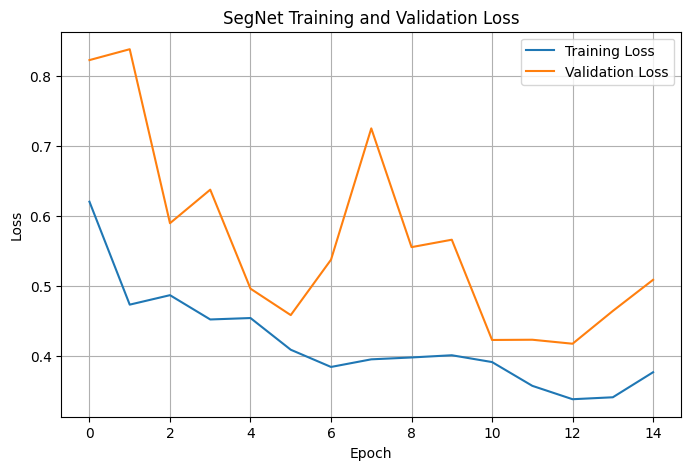


MODEL EVALUATION COMPLETED!


In [10]:

# ==========================================
# CELL 7: SEGNET MODEL EVALUATION
# ==========================================

import torch
import numpy as np
import matplotlib.pyplot as plt

model.eval()

total_intersection = 0
total_union = 0
total_prediction = 0
total_target = 0
total_correct = 0
total_pixels = 0

with torch.no_grad():

    for images, masks in test_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        # Convert predictions into binary masks
        predictions = (torch.sigmoid(outputs) >= 0.5).float()

        # Calculate metric values
        intersection = (predictions * masks).sum().item()
        union = ((predictions + masks) > 0).float().sum().item()

        total_intersection += intersection
        total_union += union
        total_prediction += predictions.sum().item()
        total_target += masks.sum().item()

        total_correct += (predictions == masks).sum().item()
        total_pixels += masks.numel()

# Calculate final metrics
epsilon = 1e-7

iou = total_intersection / (total_union + epsilon)

dice = (
    2 * total_intersection /
    (total_prediction + total_target + epsilon)
)

pixel_accuracy = total_correct / total_pixels

print("=" * 45)
print("SEGNET TEST RESULTS")
print("=" * 45)

print("Test Images:", len(test_dataset))
print("IoU Score:", round(iou, 4))
print("Dice Score:", round(dice, 4))
print("Pixel Accuracy:", round(pixel_accuracy * 100, 2), "%")

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SegNet Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

print("\nMODEL EVALUATION COMPLETED!")


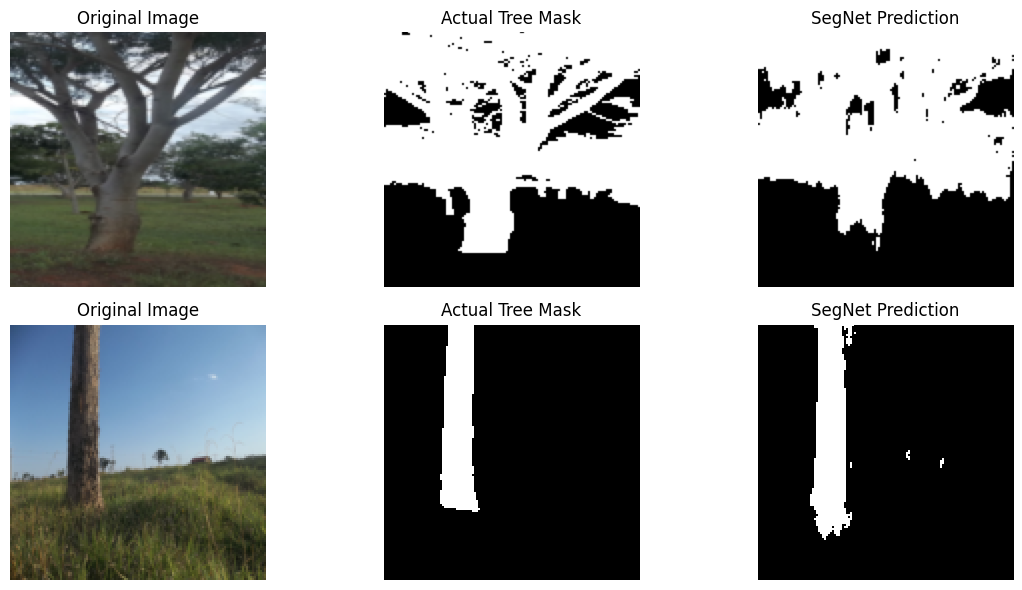

PREDICTION VISUALIZATION COMPLETED!


In [11]:

# ==========================================
# CELL 8: VISUALIZE SEGNET PREDICTIONS
# ==========================================

import matplotlib.pyplot as plt
import torch
import numpy as np

model.eval()

images, masks = next(iter(test_loader))

with torch.no_grad():
    outputs = model(images.to(device))
    predictions = (torch.sigmoid(outputs) >= 0.5).float()

# Display up to 4 test images
num_images = min(4, len(images))

plt.figure(figsize=(12, num_images * 3))

for i in range(num_images):

    original = images[i].permute(1, 2, 0).numpy()
    actual_mask = masks[i, 0].numpy()
    predicted_mask = predictions[i, 0].cpu().numpy()

    plt.subplot(num_images, 3, i * 3 + 1)
    plt.imshow(original)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(num_images, 3, i * 3 + 2)
    plt.imshow(actual_mask, cmap="gray")
    plt.title("Actual Tree Mask")
    plt.axis("off")

    plt.subplot(num_images, 3, i * 3 + 3)
    plt.imshow(predicted_mask, cmap="gray")
    plt.title("SegNet Prediction")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("PREDICTION VISUALIZATION COMPLETED!")


In [12]:

# ==========================================
# CELL 9: SAVE FINAL MODEL AND RESULTS
# ==========================================

import torch
import os
import zipfile

# Create project folder
save_dir = "/content/SegNet_Tree_Project"
os.makedirs(save_dir, exist_ok=True)

# Save trained model
model_path = os.path.join(save_dir, "SegNet_Tree_Model.pth")
torch.save(model.state_dict(), model_path)

# Save evaluation results
results_path = os.path.join(save_dir, "Evaluation_Results.txt")

with open(results_path, "w") as f:
    f.write("SEGNET TREE SEGMENTATION PROJECT\n")
    f.write("================================\n\n")
    f.write("Dataset: Tree Segmentation Dataset\n")
    f.write("Total Images: 49\n")
    f.write("Training Images: 34\n")
    f.write("Validation Images: 7\n")
    f.write("Testing Images: 8\n\n")
    f.write("Model: SegNet\n")
    f.write("Device: CPU\n")
    f.write("Epochs: 15\n")
    f.write("Trainable Parameters: 574849\n\n")
    f.write("Best Validation Loss: 0.4172\n")
    f.write("IoU Score: 0.7509\n")
    f.write("Dice Score: 0.8577\n")
    f.write("Pixel Accuracy: 86.22%\n")

# Save loss history
loss_path = os.path.join(save_dir, "Training_Loss.txt")

with open(loss_path, "w") as f:
    f.write("Epoch,Training Loss,Validation Loss\n")

    for i in range(len(train_losses)):
        f.write(
            f"{i+1},{train_losses[i]:.6f},{val_losses[i]:.6f}\n"
        )

# Create ZIP file
zip_path = "/content/SegNet_Tree_Project.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(save_dir):
        for file in files:
            file_path = os.path.join(root, file)
            zipf.write(
                file_path,
                os.path.relpath(file_path, save_dir)
            )

print("MODEL AND RESULTS SAVED SUCCESSFULLY!")
print("\nSaved files:")
print("1. SegNet_Tree_Model.pth")
print("2. Evaluation_Results.txt")
print("3. Training_Loss.txt")
print("4. SegNet_Tree_Project.zip")

print("\nZIP file location:", zip_path)


MODEL AND RESULTS SAVED SUCCESSFULLY!

Saved files:
1. SegNet_Tree_Model.pth
2. Evaluation_Results.txt
3. Training_Loss.txt
4. SegNet_Tree_Project.zip

ZIP file location: /content/SegNet_Tree_Project.zip


In [13]:

from google.colab import files
files.download("/content/SegNet_Tree_Project.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>